In [15]:
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

data = pd.read_csv("penyakit_jantung.csv")
data.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,female,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,female,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,male,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,female,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,male,0,120,354,0,1,163,1,0.6,2,0,2,1


In [13]:
from scipy.stats import shapiro

# Langkah 2: Uji Shapiro-Wilk pada Data Asli
thalach_data = data['thalach']
shapiro_test_result = shapiro(thalach_data)
print("Original Shapiro-Wilk Test:")
print("Statistic:", shapiro_test_result.statistic)
print("p-value:", shapiro_test_result.pvalue)


Original Shapiro-Wilk Test:
Statistic: 0.9763153561573904
p-value: 6.620819654256617e-05


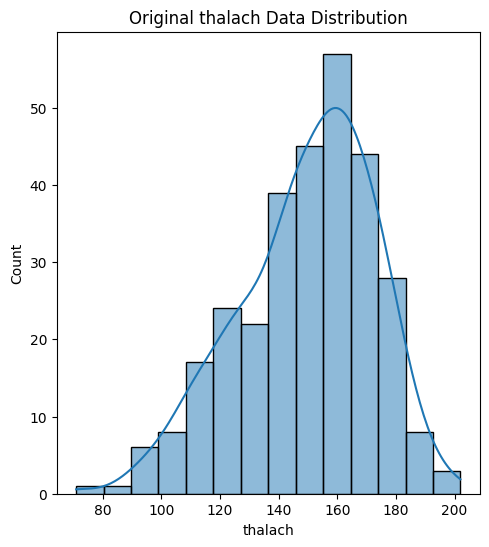

In [14]:
# Langkah 5: Visualisasi Distribusi Data Sebelum dan Sesudah Standardisasi
plt.figure(figsize=(12, 6))

# Distribusi Data Asli
plt.subplot(1, 2, 1)
sns.histplot(thalach_data, kde=True)
plt.title('Original thalach Data Distribution')

plt.show()

In [23]:
from scipy.stats import norm

# Langkah 2: Urutkan Data dan Hitung Mean serta Varians
thalach_data = data['thalach']
sorted_data = np.sort(thalach_data)
mean_data = np.mean(thalach_data)
n = len(thalach_data)

# Langkah 3: Hitung Faktor m
m = norm.ppf([(i - 0.375) / (n + 0.25) for i in range(1, n + 1)])

# Langkah 4: Hitung Faktor a
def compute_a(m):
    u = np.zeros(n)
    for i in range(n):
        u[i] = m[i] - np.mean(m)
    c = np.dot(u, u)
    a = u / np.sqrt(c)
    return a

a = compute_a(m)

# Langkah 5: Hitung Statistik W

b = np.dot(a, sorted_data)
W = (b ** 2) / np.sum((sorted_data - mean_data) ** 2)

print("Shapiro-Wilk :", W)

Shapiro-Wilk : 0.9766678478748453


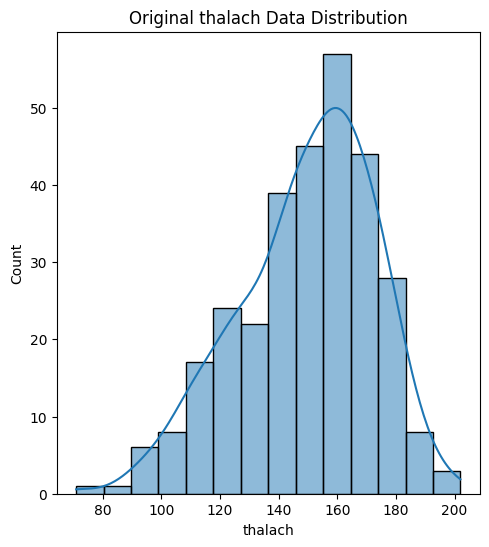

In [20]:
# Langkah 8: Visualisasi Distribusi Data Sebelum dan Sesudah Standardisasi
plt.figure(figsize=(12, 6))

# Distribusi Data Asli
plt.subplot(1, 2, 1)
sns.histplot(thalach_data, kde=True)
plt.title('Original thalach Data Distribution')

plt.show()